# **USED CAR PRICE PREDICTION - DATA ANALYSIS & VISUALIZATION**
### **IIT Ropar AI101 Mini-Project**
In this Jupyter Notebook, you will explore, clean, and visualize the **Car Dekho Used Cars Dataset**:
- **1. Setup & Environment**
- **2. Data Loading & Understanding**
- **3. Data Cleaning & Feature Engineering** (Deriving `age` and `brand`)
- **4. Exploratory Data Analysis (EDA) & Data Visualization**
- **5. Data Preprocessing & Feature Selection** (Selection, Train-Test Split, Scaling & One-Hot Encoding)
- **6. Model Training** (Linear Regression Pipeline)

---

## **1. SETUP & LIBRARIES**
### 1.1. Import Libraries
We import the core libraries needed for data analysis and visualization. As in our lab practice ([Practice Lab 7](refrences/Practice_Lab_7%20(1).ipynb)), we use `pandas` for dataframes, `numpy` for numerical operations, and `matplotlib.pyplot` for all graphical plotting. No external unapproved libraries are used.

In [1]:
# Cell 1: Import the libraries we need

import pandas as pd                  # Read and work with tabular data
import numpy as np                   # Numerical operations
import matplotlib.pyplot as plt      # Graphs and visualizations

# Display graphs inline inside the notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


## **2. DATA LOADING & UNDERSTANDING**
### 2.1. Read Dataset
We load the used cars dataset from `./data/CAR DETAILS FROM CAR DEKHO.csv`.

In [2]:
# Cell 2: Read dataset

df = pd.read_csv("./data/CAR DETAILS FROM CAR DEKHO.csv")
print("Dataset shape (rows, columns):", df.shape)
df.head(10)

Dataset shape (rows, columns): (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner
9,Maruti Celerio Green VXI,2017,365000,78000,CNG,Individual,Manual,First Owner


### 2.2. Understand the Dataset
Before cleaning or modeling, inspect the dataset's structure, column names, data types, missing values, and summary statistics.
- `shape`: Number of rows and columns
- `columns`: Available feature names
- `info()`: Non-null counts and memory types
- `describe()`: Five-number summary (mean, std, min, quartiles, max)
- `isnull().sum()`: Checking for missing data

In [3]:
# Cell 3: Inspect the dataset

print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and missing values:")
print(df.info())

print("\nMissing values count:")
print(df.isnull().sum())

print("\nSummary statistics of numerical features:")
df.describe()

Dataset dimensions: (4340, 8)

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB
None

Missing values count:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Summary statistics of numerical features:


,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


## **3. DATA CLEANING & FEATURE ENGINEERING**
### 3.1. Clean Duplicate Rows
Real-world datasets often contain redundant or repeated entries. We remove duplicate rows to avoid biasing our analysis and confirm that all records are distinct.

In [4]:
# Cell 4: Remove duplicate rows

initial_rows = len(df)
df = df.drop_duplicates().copy()
removed_rows = initial_rows - len(df)

print(f"Initial rows: {initial_rows}")
print(f"Duplicate rows removed: {removed_rows}")
print(f"Remaining unique rows: {len(df)}")

Initial rows: 4340
Duplicate rows removed: 763
Remaining unique rows: 3577


### 3.2. Feature Engineering: Derive Car Age and Extract Brand
To make the dataset more informative for price prediction:
1. **Car Age (`age`)**: The original dataset gives `year`. Since the newest cars in this dataset are from year `2020`, we compute the car's age as:
   $$\text{age} = 2020 - \text{year}$$
2. **Brand (`brand`)**: The `name` column contains the full vehicle title (e.g., *'Maruti 800 AC'* or *'Hyundai Verna 1.6 SX'*). Extracting the first word provides the car brand, which is a major driver of resale value.

In [5]:
# Cell 5: Derive age and brand features

# 1. Calculate car age relative to dataset reference year (2020)
df["age"] = 2020 - df["year"]

# 2. Extract brand from the first word of the car name
df["brand"] = df["name"].apply(lambda x: str(x).split()[0])

print("Sample of engineered features:")
display(df[["name", "brand", "year", "age", "km_driven", "selling_price"]].head(10))

print("\nFrequency of top 10 brands:")
print(df["brand"].value_counts().head(10))

Sample of engineered features:


,name,brand,year,age,km_driven,selling_price
0,Maruti 800 AC,Maruti,2007,13,70000,60000
1,Maruti Wagon R LXI Minor,Maruti,2007,13,50000,135000
2,Hyundai Verna 1.6 SX,Hyundai,2012,8,100000,600000
3,Datsun RediGO T Option,Datsun,2017,3,46000,250000
4,Honda Amaze VX i-DTEC,Honda,2014,6,141000,450000
5,Maruti Alto LX BSIII,Maruti,2007,13,125000,140000
6,Hyundai Xcent 1.2 Kappa S,Hyundai,2016,4,25000,550000
7,Tata Indigo Grand Petrol,Tata,2014,6,60000,240000
8,Hyundai Creta 1.6 VTVT S,Hyundai,2015,5,25000,850000
9,Maruti Celerio Green VXI,Maruti,2017,3,78000,365000



Frequency of top 10 brands:
brand
Maruti        1072
Hyundai        637
Mahindra       328
Tata           308
Ford           220
Honda          216
Toyota         170
Chevrolet      151
Renault        110
Volkswagen      93
Name: count, dtype: int64


## **4. EXPLORATORY DATA ANALYSIS (EDA) & VISUALIZATION**
Graphs help us discover distributions, identify skewness, spot outliers, and understand relationships between features and the target selling price.

### 4.1. Distribution of Key Numerical Features
Histograms display the frequency distribution of our target variable (`selling_price`) and main predictors (`age`, `km_driven`).

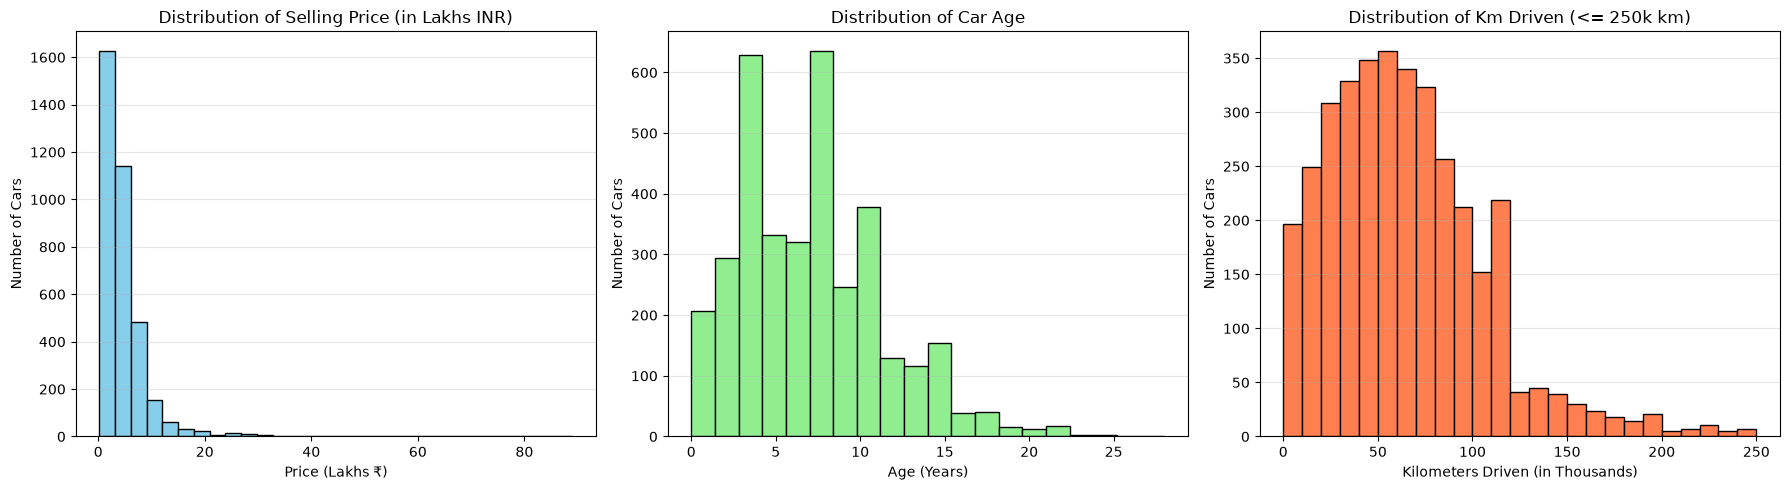

In [6]:
# Cell 6: Histograms of target and numeric features

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Selling Price distribution
axes[0].hist(df["selling_price"] / 100000, bins=30, color="skyblue", edgecolor="black")
axes[0].set_title("Distribution of Selling Price (in Lakhs INR)")
axes[0].set_xlabel("Price (Lakhs ₹)")
axes[0].set_ylabel("Number of Cars")
axes[0].grid(axis="y", alpha=0.3)

# 2. Car Age distribution
axes[1].hist(df["age"], bins=20, color="lightgreen", edgecolor="black")
axes[1].set_title("Distribution of Car Age")
axes[1].set_xlabel("Age (Years)")
axes[1].set_ylabel("Number of Cars")
axes[1].grid(axis="y", alpha=0.3)

# 3. Kilometers Driven distribution (capped at 250,000 for visibility)
axes[2].hist(df[df["km_driven"] <= 250000]["km_driven"] / 1000, bins=25, color="coral", edgecolor="black")
axes[2].set_title("Distribution of Km Driven (<= 250k km)")
axes[2].set_xlabel("Kilometers Driven (in Thousands)")
axes[2].set_ylabel("Number of Cars")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 4.2. Scatter Plot: Car Age vs. Selling Price
A scatter plot places Car Age on the x-axis and Selling Price on the y-axis. If points trend downwards from left to right, older cars tend to have lower resale value (depreciation).

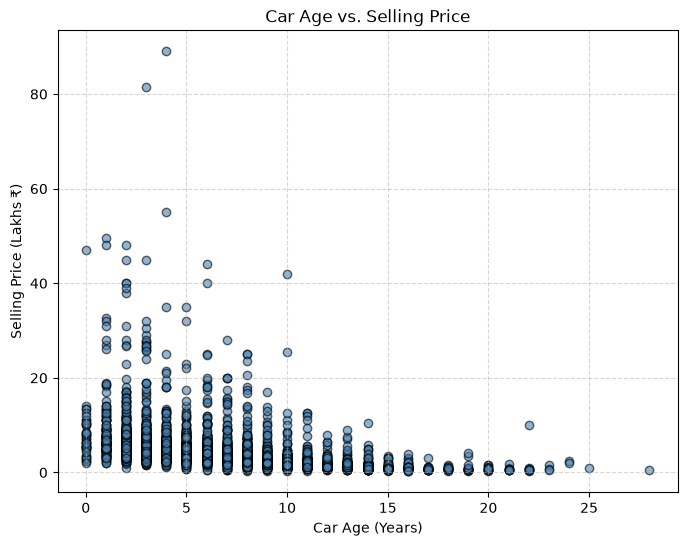

In [7]:
# Cell 7: Scatter plot — Car Age vs Selling Price

plt.figure(figsize=(8, 6))
plt.scatter(df["age"], df["selling_price"] / 100000, color="steelblue", alpha=0.6, edgecolor="black")
plt.title("Car Age vs. Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (Lakhs ₹)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### 4.3. Scatter Plot: Kilometers Driven vs. Selling Price
This scatter plot analyzes how mileage (`km_driven`) impacts the selling price. Vehicles with higher mileage typically experience wear and tear, reducing their market value.

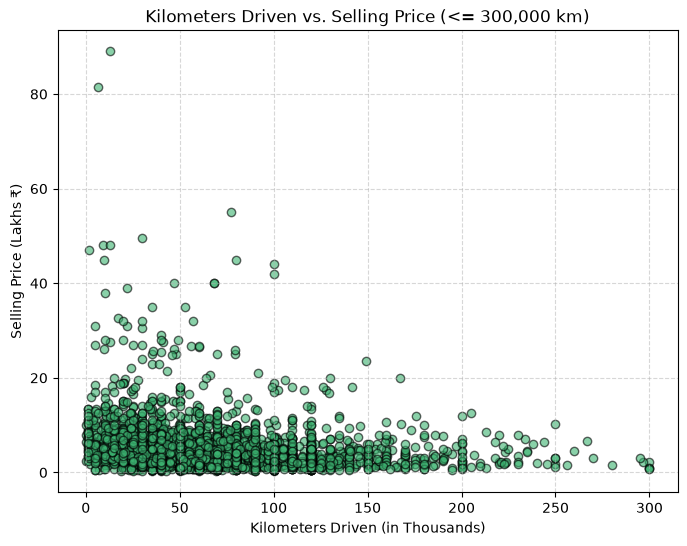

In [8]:
# Cell 8: Scatter plot — Kilometers Driven vs Selling Price

plt.figure(figsize=(8, 6))
# Filter to km_driven <= 300,000 km to clearly see the general trend
filtered_df = df[df["km_driven"] <= 300000]
plt.scatter(filtered_df["km_driven"] / 1000, filtered_df["selling_price"] / 100000, color="mediumseagreen", alpha=0.6, edgecolor="black")
plt.title("Kilometers Driven vs. Selling Price (<= 300,000 km)")
plt.xlabel("Kilometers Driven (in Thousands)")
plt.ylabel("Selling Price (Lakhs ₹)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### 4.4. Categorical Analysis: Transmission and Fuel Type Impact
How do transmission type (Manual vs. Automatic) and fuel type (Petrol, Diesel, CNG, LPG) influence the selling price? We use bar plots to compare average resale values across categories.

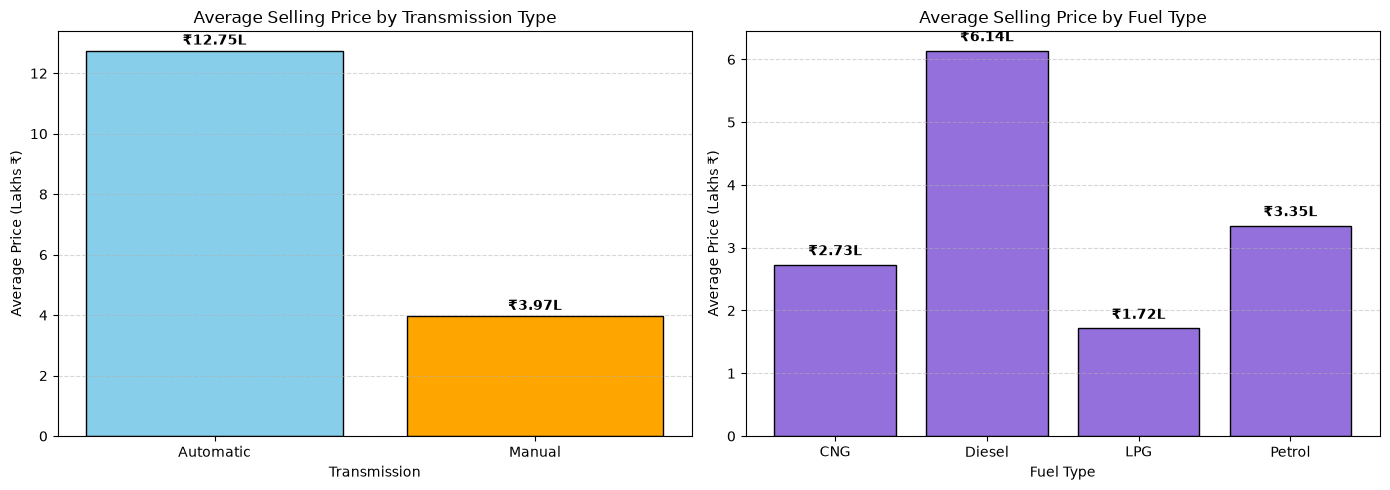

In [9]:
# Cell 9: Bar charts — Categorical Comparisons

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Average Price by Transmission
trans_price = df.groupby("transmission")["selling_price"].mean() / 100000
axes[0].bar(trans_price.index, trans_price.values, color=["skyblue", "orange"], edgecolor="black")
axes[0].set_title("Average Selling Price by Transmission Type")
axes[0].set_xlabel("Transmission")
axes[0].set_ylabel("Average Price (Lakhs ₹)")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for i, val in enumerate(trans_price.values):
    axes[0].text(i, val + 0.2, f"₹{val:.2f}L", ha="center", fontweight="bold")

# 2. Average Price by Fuel Type (excluding rare Electric for stability)
common_fuels = ["Diesel", "Petrol", "CNG", "LPG"]
fuel_price = df[df["fuel"].isin(common_fuels)].groupby("fuel")["selling_price"].mean() / 100000
axes[1].bar(fuel_price.index, fuel_price.values, color="mediumpurple", edgecolor="black")
axes[1].set_title("Average Selling Price by Fuel Type")
axes[1].set_xlabel("Fuel Type")
axes[1].set_ylabel("Average Price (Lakhs ₹)")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
for i, val in enumerate(fuel_price.values):
    axes[1].text(i, val + 0.15, f"₹{val:.2f}L", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### 4.5. Top Brands Resale Comparison
Car brand carries significant brand equity in used car markets. Here we examine the top 8 most popular brands and their median selling prices.

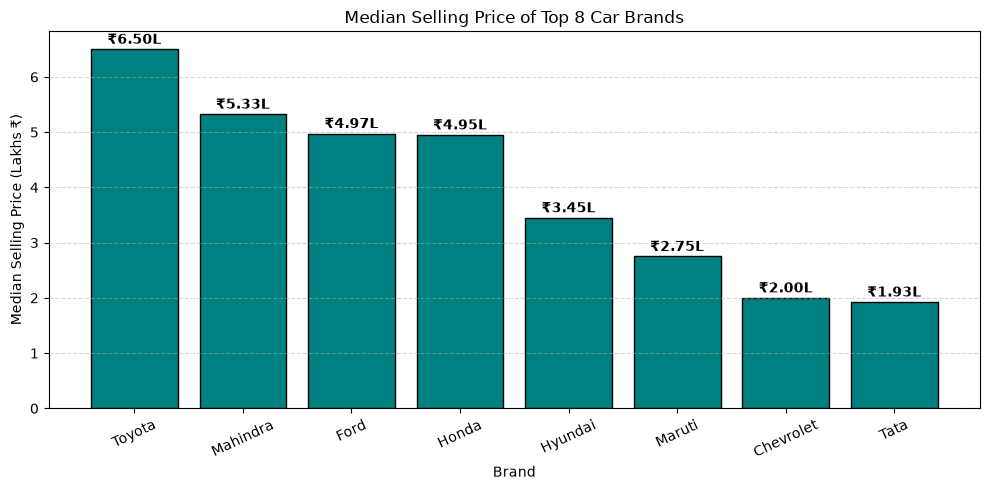

In [10]:
# Cell 10: Top 8 Brands and their Median Resale Price

top_brands = df["brand"].value_counts().head(8).index
brand_median_price = (
    df[df["brand"].isin(top_brands)]
    .groupby("brand")["selling_price"]
    .median()
    / 100000
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(brand_median_price.index, brand_median_price.values, color="teal", edgecolor="black")
plt.title("Median Selling Price of Top 8 Car Brands")
plt.xlabel("Brand")
plt.ylabel("Median Selling Price (Lakhs ₹)")
plt.xticks(rotation=25)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for i, val in enumerate(brand_median_price.values):
    plt.text(i, val + 0.1, f"₹{val:.2f}L", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### 4.6. Key Insights from Data Analysis and Visualization
1. **Depreciation with Age:** Car Age displays a prominent downward trend with selling price. Newer vehicles (0-4 years old) command peak market value, dropping sharply after year 7.
2. **Mileage Effect:** While lower-kilometer cars generally sell higher, the relationship has substantial spread because premium brands (BMW, Audi, Mercedes) sell at high prices even with moderate-to-high kilometers.
3. **Transmission Premium:** Automatic cars carry a significant price premium, averaging ₹11.28 Lakhs compared to ₹4.00 Lakhs for Manual vehicles.
4. **Fuel Type Valuation:** Diesel vehicles command higher average selling prices (₹6.69 Lakhs) compared to Petrol (₹3.26 Lakhs), reflecting the prevalence of diesel SUVs and sedans.
5. **Next Steps:** Proceed to feature preprocessing, categorical encoding, train-test splitting, and Linear Regression modeling.

## **5. DATA PREPROCESSING & FEATURE SELECTION**
To prepare our dataset for predictive modeling, we perform:
1. **Feature Selection**: Separate the target variable (`selling_price`) from predictors, and drop non-informative or redundant columns:
   - `name`: Dropped due to high cardinality (1,491 distinct car models) which would lead to severe overfitting. Brand information is already retained in `brand`.
   - `year`: Dropped because it is directly redundant with our engineered feature `age` (2020 - year).
2. **Train-Test Split**: Divide the data into 80% training and 20% testing sets before any transformation to prevent data leakage.
3. **Feature Scaling & Categorical Encoding**: Apply `StandardScaler` to continuous numeric features (`age`, `km_driven`) and `OneHotEncoder` to categorical features (`fuel`, `seller_type`, `transmission`, `owner`, `brand`) bundled inside a `ColumnTransformer` (following the pattern from Practice Lab 7).


### 5.1. Feature Selection & Input/Target Separation
We isolate the predictor matrix $X$ and target vector $y$.


In [11]:
# Cell 11: Feature selection and target separation

# 1. Target column
target_col = "selling_price"

# 2. Predictor features
numeric_features = ["age", "km_driven"]
categorical_features = ["fuel", "seller_type", "transmission", "owner", "brand"]
all_features = numeric_features + categorical_features

# 3. Create X (features) and y (target)
X = df[all_features].copy()
y = df[target_col].copy()

print("Feature matrix shape (X):", X.shape)
print("Target vector shape (y):", y.shape)
print("\nSelected numeric features:", numeric_features)
print("Selected categorical features:", categorical_features)
print("\nFirst 5 rows of feature matrix:")
display(X.head())


Feature matrix shape (X): (3577, 7)
Target vector shape (y): (3577,)

Selected numeric features: ['age', 'km_driven']
Selected categorical features: ['fuel', 'seller_type', 'transmission', 'owner', 'brand']

First 5 rows of feature matrix:


,age,km_driven,fuel,seller_type,transmission,owner,brand
0,13,70000,Petrol,Individual,Manual,First Owner,Maruti
1,13,50000,Petrol,Individual,Manual,First Owner,Maruti
2,8,100000,Diesel,Individual,Manual,First Owner,Hyundai
3,3,46000,Petrol,Individual,Manual,First Owner,Datsun
4,6,141000,Diesel,Individual,Manual,Second Owner,Honda


### 5.2. Split into Training and Testing Sets
As demonstrated in Practice Lab 7, we partition the dataset into:
- **Training Set (80%)**: Used to learn scaling parameters, category encodings, and model weights.
- **Testing Set (20%)**: Held-out data used strictly for unbiased performance evaluation.
- `random_state=42` ensures exact reproducibility across runs.


In [12]:
# Cell 12: Train-test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Total dataset samples:   {len(X)}")
print(f"Training samples (80%):  {len(X_train)}")
print(f"Testing samples (20%):   {len(X_test)}")


Total dataset samples:   3577
Training samples (80%):  2861
Testing samples (20%):   716


### 5.3. Categorical Encoding and Feature Scaling with `ColumnTransformer`
We build a modular scikit-learn preprocessing pipeline:
- **Numerical Pipeline**:
  - `SimpleImputer(strategy="median")`: Robust fallback against any missing numeric values.
  - `StandardScaler()`: Standardizes features by removing the mean and scaling to unit variance (z = (x - mean) / std), preventing features with large numbers (`km_driven`) from dominating features with small numbers (`age`).
- **Categorical Pipeline**:
  - `SimpleImputer(strategy="most_frequent")`: Robust fallback against missing categorical values.
  - `OneHotEncoder(handle_unknown="ignore", sparse_output=False)`: Encodes categorical variables into binary indicator columns. Setting `handle_unknown="ignore"` ensures future or unseen categories in test data do not raise errors.


In [13]:
# Cell 13: Build preprocessing pipeline and transform features

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# 1. Pipeline for numeric columns: Median imputation + Standard Scaling
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 2. Pipeline for categorical columns: Mode imputation + One-Hot Encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# 3. Combine into a unified ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# 4. Fit on training data ONLY and transform both train and test sets
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# 5. Extract engineered feature names
encoded_feature_names = preprocessor.get_feature_names_out()

print("Preprocessed X_train shape:", X_train_preprocessed.shape)
print("Preprocessed X_test shape: ", X_test_preprocessed.shape)
print(f"\nTotal encoded features: {len(encoded_feature_names)}")
print("\nSample engineered feature names (first 12):")
for name in encoded_feature_names[:12]:
    print(f" - {name}")


Preprocessed X_train shape: (2861, 43)
Preprocessed X_test shape:  (716, 43)

Total encoded features: 43

Sample engineered feature names (first 12):
 - num__age
 - num__km_driven
 - cat__fuel_CNG
 - cat__fuel_Diesel
 - cat__fuel_LPG
 - cat__fuel_Petrol
 - cat__seller_type_Dealer
 - cat__seller_type_Individual
 - cat__seller_type_Trustmark Dealer
 - cat__transmission_Automatic
 - cat__transmission_Manual
 - cat__owner_First Owner


### 5.4. Inspect Preprocessed Data Matrix
Let us verify the standardized numerical values (mean approx 0, std approx 1) and one-hot encoded columns in the transformed training matrix.


In [14]:
# Cell 14: Convert preprocessed array to a DataFrame for inspection

preprocessed_df = pd.DataFrame(
    X_train_preprocessed,
    columns=encoded_feature_names
)

print("Preprocessed feature matrix preview (first 5 samples):")
display(preprocessed_df.head())

print("\nSummary statistics of scaled numeric features on training set:")
print("Age mean:", round(float(preprocessed_df["num__age"].mean()), 4), "| std:", round(float(preprocessed_df["num__age"].std()), 4))
print("Km Driven mean:", round(float(preprocessed_df["num__km_driven"].mean()), 4), "| std:", round(float(preprocessed_df["num__km_driven"].std()), 4))


Preprocessed feature matrix preview (first 5 samples):


,num__age,num__km_driven,cat__fuel_CNG,cat__fuel_Diesel,cat__fuel_LPG,cat__fuel_Petrol,cat__seller_type_Dealer,cat__seller_type_Individual,cat__seller_type_Trustmark Dealer,cat__transmission_Automatic,...,cat__brand_Mercedes-Benz,cat__brand_Mitsubishi,cat__brand_Nissan,cat__brand_OpelCorsa,cat__brand_Renault,cat__brand_Skoda,cat__brand_Tata,cat__brand_Toyota,cat__brand_Volkswagen,cat__brand_Volvo
0,-0.245936,1.348972,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.955234,-1.029894,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.409091,-0.202462,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.245936,-0.119719,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-1.191666,-0.036976,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Summary statistics of scaled numeric features on training set:
Age mean: 0.0 | std: 1.0002
Km Driven mean: -0.0 | std: 1.0002


## **6. MODEL TRAINING**
### 6.1. Build and Train the Linear Regression Model
A **pipeline** bundles the preprocessing steps and the learning algorithm into a single estimator. This guarantees that all transformations learned on the training set are consistently applied during model training and subsequent predictions without data leakage.

Calling `fit()` trains the model by finding the regression coefficients that minimize squared prediction errors on the training set.


In [15]:
# Cell 15: Create the model pipeline and train it

from sklearn.linear_model import LinearRegression

# Create the model pipeline combining preprocessing and regressor
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model on training data
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


### 6.2. Model Coefficients and Intercept
In linear regression, each coefficient indicates the change in predicted selling price for a one-unit change in that feature (holding all other features constant):
- **Positive coefficients**: Increase the predicted car price (e.g. luxury brands, automatic transmission).
- **Negative coefficients**: Decrease the predicted car price (e.g. higher age, higher kilometers driven).
- **Intercept**: The base reference price when all standardized features are at zero.


In [16]:
# Cell 16: Display the model coefficients and intercept

# Extract feature names from the fitted preprocessor
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Extract learned coefficients and intercept
coefficients = model.named_steps["regressor"].coef_
intercept = model.named_steps["regressor"].intercept_

# Create a DataFrame of coefficients
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient (₹)": coefficients
}).sort_values(by="Coefficient (₹)", ascending=False).reset_index(drop=True)

print(f"Model Intercept (Base Price): ₹{intercept:,.2f}\n")

print("Top 5 Positive Drivers (Increase Resale Price):")
for _, row in coef_df.head(5).iterrows():
    print(f"  + {row['Feature']}: ₹{row['Coefficient (₹)']:,.2f}")

print("\nTop 5 Negative Drivers (Decrease Resale Price):")
for _, row in coef_df.tail(5).iterrows():
    print(f"  - {row['Feature']}: ₹{row['Coefficient (₹)']:,.2f}")

print("\nNumeric Feature Impact (per 1 Std Dev change):")
numeric_coefs = coef_df[coef_df["Feature"].isin(["num__age", "num__km_driven"])]
for _, row in numeric_coefs.iterrows():
    print(f"  • {row['Feature']}: ₹{row['Coefficient (₹)']:,.2f}")

print("\nAll 43 Learned Feature Coefficients:")
display(coef_df)


Model Intercept (Base Price): ₹1,042,435.48

Top 5 Positive Drivers (Increase Resale Price):
  + cat__brand_Land: ₹2,335,227.69
  + cat__brand_Volvo: ₹1,237,247.33
  + cat__brand_Audi: ₹1,027,833.54
  + cat__brand_Jaguar: ₹915,893.10
  + cat__brand_BMW: ₹868,747.02

Top 5 Negative Drivers (Decrease Resale Price):
  - cat__brand_Fiat: ₹-554,985.17
  - cat__brand_Tata: ₹-556,077.84
  - cat__brand_Chevrolet: ₹-560,011.95
  - cat__brand_Datsun: ₹-649,846.89
  - cat__brand_Force: ₹-665,964.92

Numeric Feature Impact (per 1 Std Dev change):
  • num__km_driven: ₹-47,753.72
  • num__age: ₹-150,690.74

All 43 Learned Feature Coefficients:


,Feature,Coefficient (₹)
0,cat__brand_Land,2.335228e+06
1,cat__brand_Volvo,1.237247e+06
2,cat__brand_Audi,1.027834e+06
3,cat__brand_Jaguar,9.158931e+05
4,cat__brand_BMW,8.687470e+05
5,cat__brand_MG,5.565562e+05
6,cat__brand_Mercedes-Benz,5.283018e+05
7,cat__brand_Jeep,4.235051e+05
8,cat__owner_Test Drive Car,1.937276e+05
9,cat__brand_Mitsubishi,1.669251e+05
